In [1]:
import sqlite3
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

conn = sqlite3.connect("agriculture.db")

crop_clean = pd.read_sql_query(
    "SELECT * FROM crop_recommendation_clean",
    conn
)

train_clean = pd.read_sql_query(
    "SELECT * FROM agri_yield_train_clean",
    conn
)

test_clean = pd.read_sql_query(
    "SELECT * FROM agri_yield_test_clean",
    conn
)

print("Crop Recommendation Shape:", crop_clean.shape)
print("Yield Train Shape:", train_clean.shape)
print("Yield Test Shape:", test_clean.shape)

DatabaseError: Execution failed on sql 'SELECT * FROM crop_recommendation_clean': no such table: crop_recommendation_clean

In [2]:
import sqlite3
import os

print("Current working directory:")
print(os.getcwd())

print("\nDatabase path:")
print(os.path.abspath("agriculture.db"))

print("\nDatabase exists:")
print(os.path.exists("agriculture.db"))

Current working directory:
C:\Users\ADMIN

Database path:
C:\Users\ADMIN\agriculture.db

Database exists:
True


In [3]:
conn = sqlite3.connect("agriculture.db")

tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
    """,
    conn
)

display(tables)

conn.close()

,name


In [4]:
import os

print(os.getcwd())
print(os.path.abspath("agriculture.db"))

C:\Users\ADMIN
C:\Users\ADMIN\agriculture.db


In [5]:
print(os.listdir())

['.anaconda', '.bash_history', '.cache', '.codex', '.conda', '.continuum', '.copilot', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.matplotlib', '.streamlit', '.vscode', '.vscode-shared', '01.Introduction to python.ipynb', '02. Variable.ipynb', '02.1variables (1).ipynb', '03. Data Types.ipynb', '04.Type Casting.ipynb', '05. String.ipynb', '06. String slicing, Functions.ipynb', '07. String_Functions.ipynb', '08. string Functions.ipynb', '09.Operators.ipynb', '1. Object Oriented Programming.ipynb', '1. Regular Expression.ipynb', '1.Exception Handling.ipynb', '1.Pandas.ipynb', '10 If-else.ipynb', '11.Nested if else statement.ipynb', '12. List (1).ipynb', '13. List Function.ipynb', '14. List_function.ipynb', '15.Lists.ipynb', '16.List and Tuple (1).ipynb', '17.1 Nested For loop.ipynb', '17.Tuple.ipynb', '18. Tuples (1).ipynb', '19. For_loop.ipynb', '2. Regular Expression.ipynb', '2.(a) Numpy.ipynb', '2.Encapsulation.ipynb', '2.Pandas .ipynb', '20. fo

In [6]:
import sqlite3
import pandas as pd
import numpy as np
import os

db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

print("Database exists:", os.path.exists(db_path))
print("Database path:", db_path)

conn = sqlite3.connect(db_path)

Database exists: True
Database path: C:\Users\ADMIN\smart agricultural analytics\agriculture.db


In [7]:
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
    """,
    conn
)

display(tables)

,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test
3,crop_recommendation_clean
4,agri_yield_train_clean
5,agri_yield_test_clean


In [8]:
crop_clean = pd.read_sql_query(
    "SELECT * FROM crop_recommendation_clean",
    conn
)

train_clean = pd.read_sql_query(
    "SELECT * FROM agri_yield_train_clean",
    conn
)

test_clean = pd.read_sql_query(
    "SELECT * FROM agri_yield_test_clean",
    conn
)

print("Crop Recommendation:", crop_clean.shape)
print("Yield Train:", train_clean.shape)
print("Yield Test:", test_clean.shape)

Crop Recommendation: (2200, 23)
Yield Train: (10000, 9)
Yield Test: (2000, 8)


In [9]:
print("CROP COLUMNS")
print(crop_clean.columns.tolist())

print("\nYIELD TRAIN COLUMNS")
print(train_clean.columns.tolist())

print("\nYIELD TEST COLUMNS")
print(test_clean.columns.tolist())

CROP COLUMNS
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency']

YIELD TRAIN COLUMNS
['field_id', 'soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi', 'yield']

YIELD TEST COLUMNS
['field_id', 'soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi']


In [10]:
print("CROP DATA TYPES")
print(crop_clean.dtypes)

print("\nYIELD TRAIN DATA TYPES")
print(train_clean.dtypes)

CROP DATA TYPES
N                           int64
P                           int64
K                           int64
temperature               float64
humidity                  float64
ph                        float64
rainfall                  float64
label                      object
soil_moisture             float64
soil_type                   int64
sunlight_exposure         float64
wind_speed                float64
co2_concentration         float64
organic_matter            float64
irrigation_frequency        int64
crop_density              float64
pest_pressure             float64
fertilizer_usage          float64
growth_stage                int64
urban_area_proximity      float64
water_source_type           int64
frost_risk                float64
water_usage_efficiency    float64
dtype: object

YIELD TRAIN DATA TYPES
field_id           object
soil_ph           float64
organic_matter    float64
sand_pct          float64
temperature       float64
humidity            int64
rainfall

In [11]:
crop_fe = crop_clean.copy()

train_fe = train_clean.copy()

test_fe = test_clean.copy()

print("Crop FE shape:", crop_fe.shape)
print("Yield Train FE shape:", train_fe.shape)
print("Yield Test FE shape:", test_fe.shape)

Crop FE shape: (2200, 23)
Yield Train FE shape: (10000, 9)
Yield Test FE shape: (2000, 8)


In [12]:
X_crop = crop_fe.drop(columns=["label"])
y_crop = crop_fe["label"]

print("Crop Features:")
print(X_crop.columns.tolist())

print("\nCrop Target:")
print(y_crop.name)

Crop Features:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency']

Crop Target:
label


In [13]:
X_yield = train_fe.drop(columns=["yield", "field_id"])
y_yield = train_fe["yield"]

X_yield_test = test_fe.drop(columns=["field_id"])

print("Yield Features:")
print(X_yield.columns.tolist())

print("\nYield Target:")
print(y_yield.name)

Yield Features:
['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi']

Yield Target:
yield


In [14]:
crop_numeric = X_crop.select_dtypes(
    include=np.number
).columns.tolist()

crop_categorical = X_crop.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Crop Numerical Features:")
print(crop_numeric)

print("\nCrop Categorical Features:")
print(crop_categorical)

Crop Numerical Features:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency']

Crop Categorical Features:
[]


In [15]:
yield_numeric = X_yield.select_dtypes(
    include=np.number
).columns.tolist()

yield_categorical = X_yield.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Yield Numerical Features:")
print(yield_numeric)

print("\nYield Categorical Features:")
print(yield_categorical)

Yield Numerical Features:
['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi']

Yield Categorical Features:
[]


In [16]:
print("Crop zero values:")
print((crop_fe.select_dtypes(include=np.number) == 0).sum())

Crop zero values:
N                         27
P                          0
K                          0
temperature                0
humidity                   0
ph                         0
rainfall                   0
soil_moisture              0
soil_type                  0
sunlight_exposure          0
wind_speed                 0
co2_concentration          0
organic_matter             0
irrigation_frequency       0
crop_density               0
pest_pressure              0
fertilizer_usage           0
growth_stage               0
urban_area_proximity       0
water_source_type          0
frost_risk                 0
water_usage_efficiency     0
dtype: int64


In [17]:
print("Yield zero values:")
print((train_fe.select_dtypes(include=np.number) == 0).sum())

Yield zero values:
soil_ph           0
organic_matter    0
sand_pct          0
temperature       0
humidity          0
rainfall          0
ndvi              0
yield             0
dtype: int64


In [18]:
crop_fe["NPK_Total"] = (
    crop_fe["N"]
    + crop_fe["P"]
    + crop_fe["K"]
)

In [19]:
crop_fe["N_P_Ratio"] = crop_fe["N"] / crop_fe["P"].replace(0, np.nan)

In [20]:
crop_fe["N_K_Ratio"] = crop_fe["N"] / crop_fe["K"].replace(0, np.nan)

In [21]:
crop_fe["P_K_Ratio"] = crop_fe["P"] / crop_fe["K"].replace(0, np.nan)

In [22]:
crop_fe["Temperature_Humidity"] = (
    crop_fe["temperature"]
    * crop_fe["humidity"]
)

In [23]:
crop_fe["Temperature_Rainfall"] = (
    crop_fe["temperature"]
    * crop_fe["rainfall"]
)

In [24]:
crop_fe["Humidity_Rainfall"] = (
    crop_fe["humidity"]
    * crop_fe["rainfall"]
)

In [25]:
crop_fe["Moisture_Rainfall_Ratio"] = (
    crop_fe["soil_moisture"]
    / crop_fe["rainfall"].replace(0, np.nan)
)

In [26]:
crop_fe["Irrigation_Water_Efficiency"] = (
    crop_fe["irrigation_frequency"]
    * crop_fe["water_usage_efficiency"]
)

In [27]:
crop_fe["Density_Pest_Interaction"] = (
    crop_fe["crop_density"]
    * crop_fe["pest_pressure"]
)

In [28]:
print("New Crop Features:")

new_crop_features = [
    "NPK_Total",
    "N_P_Ratio",
    "N_K_Ratio",
    "P_K_Ratio",
    "Temperature_Humidity",
    "Temperature_Rainfall",
    "Humidity_Rainfall",
    "Moisture_Rainfall_Ratio",
    "Irrigation_Water_Efficiency",
    "Density_Pest_Interaction"
]

print(new_crop_features)

New Crop Features:
['NPK_Total', 'N_P_Ratio', 'N_K_Ratio', 'P_K_Ratio', 'Temperature_Humidity', 'Temperature_Rainfall', 'Humidity_Rainfall', 'Moisture_Rainfall_Ratio', 'Irrigation_Water_Efficiency', 'Density_Pest_Interaction']


In [29]:
display(crop_fe[new_crop_features].head())

,NPK_Total,N_P_Ratio,N_K_Ratio,P_K_Ratio,Temperature_Humidity,Temperature_Rainfall,Humidity_Rainfall,Moisture_Rainfall_Ratio,Irrigation_Water_Efficiency,Density_Pest_Interaction
0,175,2.142857,2.093023,0.976744,1712.196283,4237.241986,16641.270870,0.145101,4.773173,676.535048
1,184,1.465517,2.073171,1.414634,1748.595734,4934.395694,18204.892093,0.056699,7.010687,1255.362923
2,159,1.090909,1.363636,1.250000,1893.744627,6072.354751,21729.738241,0.111242,3.035541,13.090693
3,149,2.114286,1.850000,0.875000,2123.482908,6433.734530,19467.583326,0.107911,1.273341,261.742948
4,162,1.857143,1.857143,1.000000,1642.720357,5288.545993,21439.015172,0.107478,7.736013,537.651961


In [30]:
train_fe["Temperature_Humidity"] = (
    train_fe["temperature"]
    * train_fe["humidity"]
)

test_fe["Temperature_Humidity"] = (
    test_fe["temperature"]
    * test_fe["humidity"]
)

In [31]:
train_fe["Temperature_Rainfall"] = (
    train_fe["temperature"]
    * train_fe["rainfall"]
)

test_fe["Temperature_Rainfall"] = (
    test_fe["temperature"]
    * test_fe["rainfall"]
)

In [32]:
train_fe["Humidity_Rainfall"] = (
    train_fe["humidity"]
    * train_fe["rainfall"]
)

test_fe["Humidity_Rainfall"] = (
    test_fe["humidity"]
    * test_fe["rainfall"]
)

In [33]:
train_fe["NDVI_Rainfall"] = (
    train_fe["ndvi"]
    * train_fe["rainfall"]
)

test_fe["NDVI_Rainfall"] = (
    test_fe["ndvi"]
    * test_fe["rainfall"]
)

In [34]:
train_fe["NDVI_Temperature"] = (
    train_fe["ndvi"]
    * train_fe["temperature"]
)

test_fe["NDVI_Temperature"] = (
    test_fe["ndvi"]
    * test_fe["temperature"]
)

In [35]:
train_fe["OrganicMatter_Sand"] = (
    train_fe["organic_matter"]
    * train_fe["sand_pct"]
)

test_fe["OrganicMatter_Sand"] = (
    test_fe["organic_matter"]
    * test_fe["sand_pct"]
)

In [36]:
yield_new_features = [
    "Temperature_Humidity",
    "Temperature_Rainfall",
    "Humidity_Rainfall",
    "NDVI_Rainfall",
    "NDVI_Temperature",
    "OrganicMatter_Sand"
]

display(train_fe[yield_new_features].head())

,Temperature_Humidity,Temperature_Rainfall,Humidity_Rainfall,NDVI_Rainfall,NDVI_Temperature,OrganicMatter_Sand
0,1764.0,2777.04,7714.0,50.692,11.592,110.656
1,2098.2,3397.47,9851.4,74.517,15.871,147.132
2,1821.6,3019.44,7220.4,70.016,17.664,138.000
3,2338.4,4596.88,12268.7,96.286,18.352,141.112
4,2000.0,4315.00,13808.0,107.012,15.500,110.466


In [37]:
print("Crop infinite values:")
print(np.isinf(crop_fe.select_dtypes(include=np.number)).sum().sum())

print("\nYield train infinite values:")
print(np.isinf(train_fe.select_dtypes(include=np.number)).sum().sum())

print("\nYield test infinite values:")
print(np.isinf(test_fe.select_dtypes(include=np.number)).sum().sum())

Crop infinite values:
0

Yield train infinite values:
0

Yield test infinite values:
0


In [38]:
print("Crop missing values:")
print(crop_fe.isnull().sum())

print("\nYield train missing values:")
print(train_fe.isnull().sum())

print("\nYield test missing values:")
print(test_fe.isnull().sum())

Crop missing values:
N                              0
P                              0
K                              0
temperature                    0
humidity                       0
ph                             0
rainfall                       0
label                          0
soil_moisture                  0
soil_type                      0
sunlight_exposure              0
wind_speed                     0
co2_concentration              0
organic_matter                 0
irrigation_frequency           0
crop_density                   0
pest_pressure                  0
fertilizer_usage               0
growth_stage                   0
urban_area_proximity           0
water_source_type              0
frost_risk                     0
water_usage_efficiency         0
NPK_Total                      0
N_P_Ratio                      0
N_K_Ratio                      0
P_K_Ratio                      0
Temperature_Humidity           0
Temperature_Rainfall           0
Humidity_Rainfall     

In [39]:
print("Original Crop Features:", crop_clean.shape[1])
print("Engineered Crop Features:", crop_fe.shape[1])

print("\nOriginal Yield Features:", train_clean.shape[1])
print("Engineered Yield Features:", train_fe.shape[1])

Original Crop Features: 23
Engineered Crop Features: 33

Original Yield Features: 9
Engineered Yield Features: 15


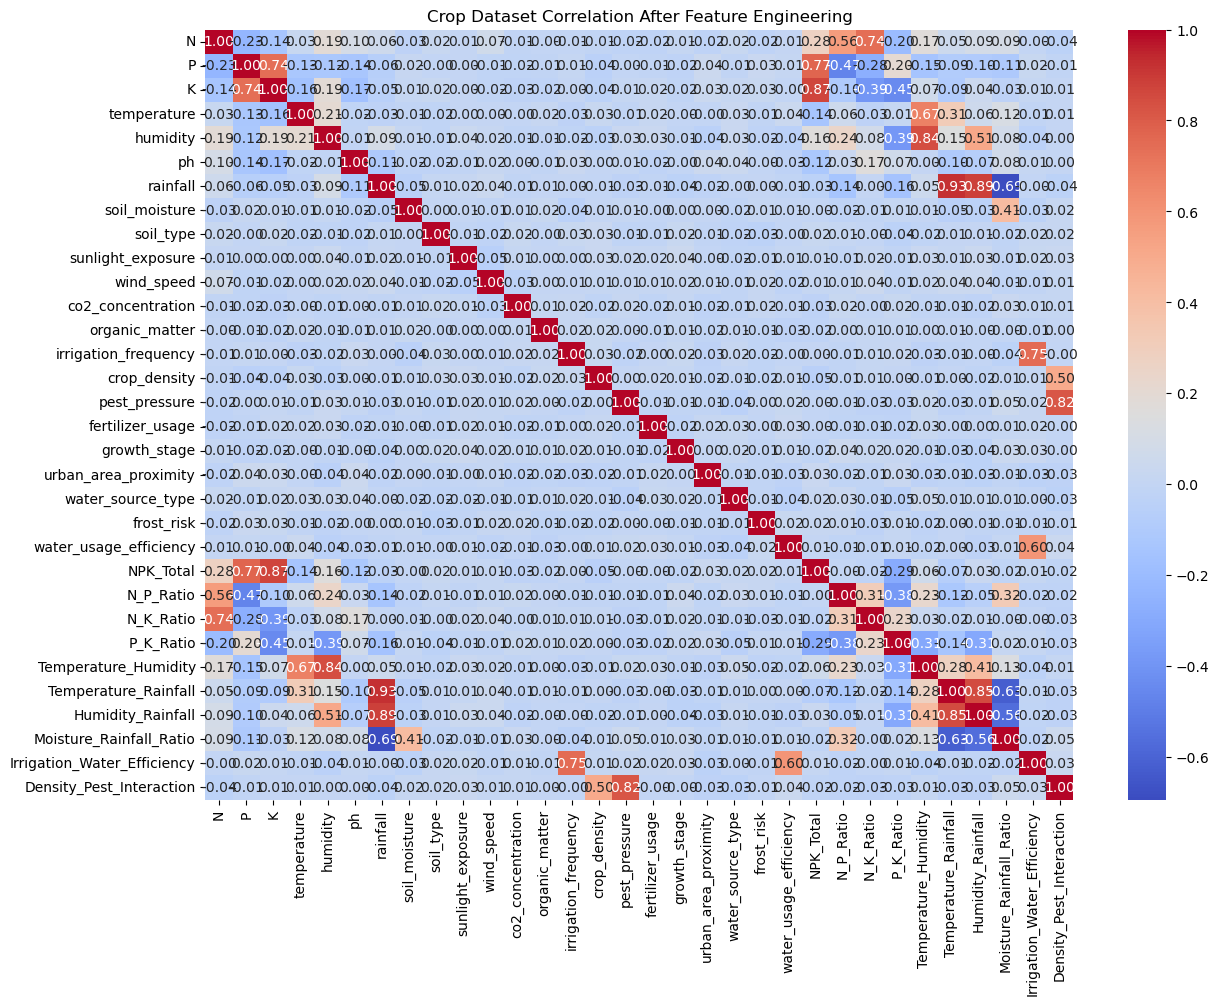

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
crop_numeric_fe = crop_fe.select_dtypes(
    include=np.number
)

crop_corr = crop_numeric_fe.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    crop_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Crop Dataset Correlation After Feature Engineering")
plt.show()

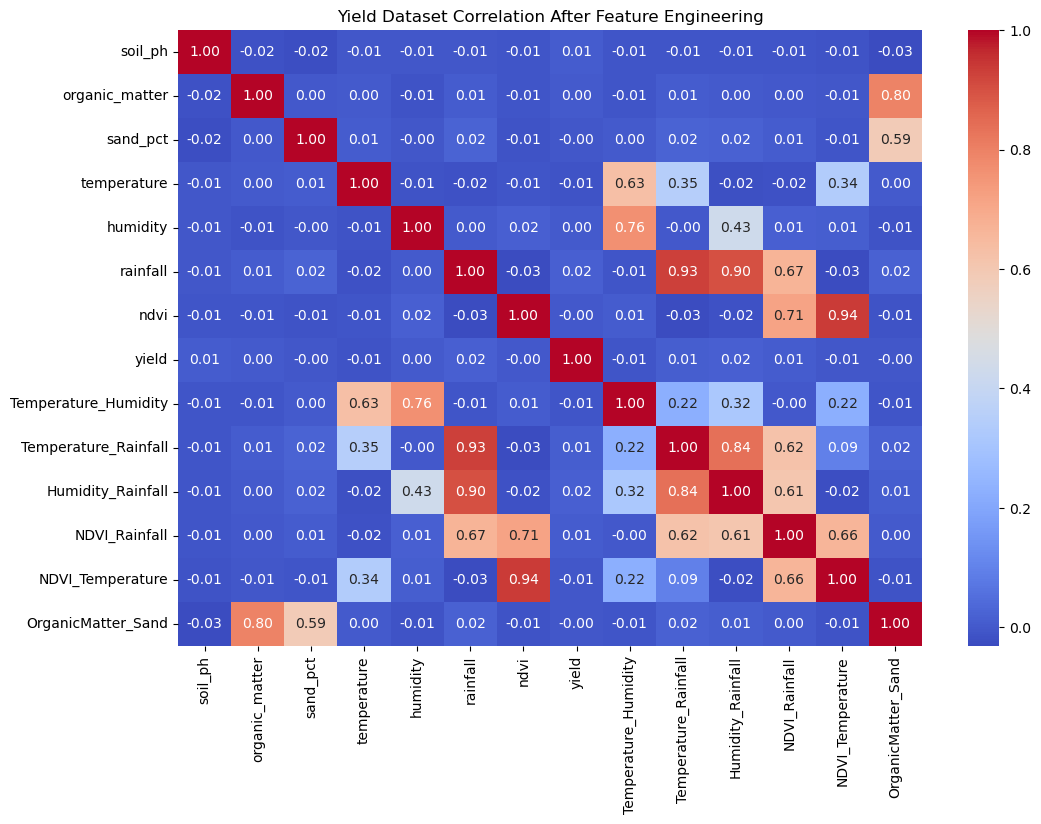

In [44]:
yield_numeric_fe = train_fe.select_dtypes(
    include=np.number
)

yield_corr = yield_numeric_fe.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    yield_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Yield Dataset Correlation After Feature Engineering")
plt.show()

In [45]:
yield_target_corr = (
    train_fe
    .select_dtypes(include=np.number)
    .corr()["yield"]
    .sort_values(ascending=False)
)

print(yield_target_corr)

yield                   1.000000
rainfall                0.016959
Humidity_Rainfall       0.015530
Temperature_Rainfall    0.010961
NDVI_Rainfall           0.008303
soil_ph                 0.007098
organic_matter          0.002207
humidity                0.001252
ndvi                   -0.001619
sand_pct               -0.003933
OrganicMatter_Sand     -0.004481
NDVI_Temperature       -0.006547
Temperature_Humidity   -0.008135
temperature            -0.014943
Name: yield, dtype: float64


In [46]:
print("Number of crop classes:")
print(crop_fe["label"].nunique())

print("\nCrop class distribution:")
print(crop_fe["label"].value_counts())

Number of crop classes:
22

Crop class distribution:
label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64


In [47]:
X_crop_fe = crop_fe.drop(columns=["label"])

crop_numeric_fe = X_crop_fe.select_dtypes(
    include=np.number
).columns.tolist()

crop_categorical_fe = X_crop_fe.select_dtypes(
    exclude=np.number
).columns.tolist()

print("CROP NUMERICAL FEATURES")
print(crop_numeric_fe)

print("\nCROP CATEGORICAL FEATURES")
print(crop_categorical_fe)

CROP NUMERICAL FEATURES
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency', 'NPK_Total', 'N_P_Ratio', 'N_K_Ratio', 'P_K_Ratio', 'Temperature_Humidity', 'Temperature_Rainfall', 'Humidity_Rainfall', 'Moisture_Rainfall_Ratio', 'Irrigation_Water_Efficiency', 'Density_Pest_Interaction']

CROP CATEGORICAL FEATURES
[]


In [48]:

X_yield_fe = train_fe.drop(columns=["yield", "field_id"])

X_yield_test_fe = test_fe.drop(columns=["field_id"])

yield_numeric_fe = X_yield_fe.select_dtypes(
    include=np.number
).columns.tolist()

yield_categorical_fe = X_yield_fe.select_dtypes(
    exclude=np.number
).columns.tolist()

print("YIELD NUMERICAL FEATURES")
print(yield_numeric_fe)

print("\nYIELD CATEGORICAL FEATURES")
print(yield_categorical_fe)

YIELD NUMERICAL FEATURES
['soil_ph', 'organic_matter', 'sand_pct', 'temperature', 'humidity', 'rainfall', 'ndvi', 'Temperature_Humidity', 'Temperature_Rainfall', 'Humidity_Rainfall', 'NDVI_Rainfall', 'NDVI_Temperature', 'OrganicMatter_Sand']

YIELD CATEGORICAL FEATURES
[]


In [49]:
crop_fe.to_sql(
    "crop_recommendation_fe",
    conn,
    if_exists="replace",
    index=False
)

train_fe.to_sql(
    "agri_yield_train_fe",
    conn,
    if_exists="replace",
    index=False
)

test_fe.to_sql(
    "agri_yield_test_fe",
    conn,
    if_exists="replace",
    index=False
)

print("Feature-engineered datasets saved successfully.")

Feature-engineered datasets saved successfully.


In [50]:
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table';
    """,
    conn
)

display(tables)

,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test
3,crop_recommendation_clean
4,agri_yield_train_clean
5,agri_yield_test_clean
6,crop_recommendation_fe
7,agri_yield_train_fe
8,agri_yield_test_fe
